# BƯỚC 4: HỆ THỐNG GỢI Ý VIỆC LÀM DỰA TRÊN NỘI DUNG (CONTENT-BASED FILTERING ENGINE)

---
**Mục tiêu:**
1. **Kiểm tra & Chuẩn bị dữ liệu**: dữ liệu sạch `jobs_clean.csv`, kiểm tra cấu trúc, độ đầy đủ và các giá trị bất thường.
2. **Khám phá & Trực quan hóa (EDA & Diagnostics)**: Trực quan hóa riêng biệt từng khía cạnh thị trường: tỷ lệ khuyết, hình thức làm việc, kinh nghiệm, boxplot lương, tình trạng hết hạn và top kỹ năng.
3. **Chuẩn hóa Kỹ năng & Xây dựng Content Soup**: Ánh xạ từ điển kỹ năng quy chuẩn (`CANONICAL_SKILL_MAP`), bảo toàn các ký tự công nghệ IT đặc thù (`C++`, `C#`, `.NET`, `CI/CD`) trong quá trình Tokenization và gán trọng số đặc trưng (`Title x3`, `Skills x4`, `Description x1`).
4. **Vector hóa TF-IDF & Heatmap Tương đồng**: Mã hóa văn bản thành không gian vector số học, kiểm tra mức độ tương đồng giữa các bài đăng tuyển dụng.
5. **Thiết kế Hệ thống Chấm điểm Đa thành phần (Composite Scoring Engine)**:
   - Áp dụng công thức chuẩn hóa kết hợp 5 yếu tố:
     $$\text{Score}(j, u) = 0.40 S_{skills} + 0.30 S_{text} + 0.10 S_{experience} + 0.10 S_{location/work\ mode} + 0.10 S_{salary}$$
   - Cơ chế tự động co giãn/tái chuẩn hóa trọng số khi tin tuyển dụng khuyết thông tin lương (Dynamic Weight Re-normalization).
   - Tự động sinh **Lời giải thích gợi ý (Rationale)** minh bạch cho từng công việc trong Top-K.
6. **Thử nghiệm Thực tế (Case Studies)**: Kiểm thử với các hồ sơ ứng viên điển hình (trong đó có hồ sơ chuẩn: Python, SQL, Machine Learning | 1 năm | Hà Nội | Remote/Hybrid | Lương >= 20 triệu).
7. **Đo lường & Đánh giá Hiệu năng (RecSys Evaluation)**: Đánh giá định lượng trên 25 Benchmark Test Profiles với đầy đủ các thước đo: **Precision@K, NDCG@K, Intra-List Diversity (ILD@K), Skill Coverage Rate (SCR@K), Catalog Coverage**.


## 1. Nạp Tập Dữ Liệu Sạch (Cleaned Dataset Ingestion)

Nạp tập dữ liệu đã qua chu trình tiền xử lý, chuẩn hóa các trường số và khử trùng lặp thực thể (`jobs_clean.csv`).


In [17]:
import os
import re
import pandas as pd
import numpy as np

# 1. Tự động xác định đường dẫn gốc dự án
current_dir = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
project_root = current_dir
while not os.path.exists(os.path.join(project_root, 'data')) and os.path.dirname(project_root) != project_root:
    project_root = os.path.dirname(project_root)

csv_path = os.path.join(project_root, 'data', 'notebook', 'content_base', 'jobs_clean.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join(project_root, 'data', 'cleaned', 'jobs_clean.csv')

# 2. Đọc file CSV dữ liệu sạch mới nhất
jobs = pd.read_csv(csv_path)
print(f" Đã nạp thành công dữ liệu mới nhất: {jobs.shape[0]:,} dòng x {jobs.shape[1]} cột")
print(f" Nguồn dữ liệu: {csv_path}")
jobs.head(3)


 Đã nạp thành công dữ liệu mới nhất: 4,536 dòng x 18 cột
 Nguồn dữ liệu: c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\data\notebook\content_base\jobs_clean.csv


,job_id,company_name,title,description_clean,required_skills,preferred_skills,experience_min,experience_max,location,city,salary_min,salary_max,employment_type,work_mode,deadline,is_active,job_url,company_logo_url
0,topcv_2136013,1 THÀNH VIÊN CÔNG NGHỆ GIÁO DỤC SOTATEK,Kỹ Sư Hạ Tầng Công Nghệ Thông Tin,"1. Phụ trách lắp đặt, cấu hình và bảo trì các ...","It - Phần Mềm, Sản Xuất, Tiếng trung giao tiếp...",NaN,1.0,1.0,"KCN Phước Nam 2, Ninh Thuận cũ, Xã Thuận Nam, ...",Khác,NaN,40000000.0,Full-time,Onsite,2026-11-08,True,https://www.topcv.vn/viec-lam/ky-su-ha-tang-co...,https://static.topcv.vn/company_logos/l4PqvWTq...
1,topcv_1986323,1 THÀNH VIÊN ISOFHCARE,Chuyên Viên BA Nghiệp Vụ,Hỗ trợ Phân tích Yêu cầu: Làm việc dưới sự hướ...,"Chuyên môn công nghệ thông tin khác, It - Phần...",NaN,3.0,3.0,"Tòa nhà One Mount. 458 Minh Khai, Phường Hai B...",Hà Nội,NaN,25000000.0,Full-time,Onsite,2026-11-25,True,https://www.topcv.vn/viec-lam/chuyen-vien-ba-n...,https://static.topcv.vn/company_logos/cong-ty-...
2,topcv_2077790,1 THÀNH VIÊN ISOFHCARE,Nhân Viên Phân Tích Yêu Cầu Ứng Dụng (BA),"Business Analyst chịu trách nhiệm thu thập, ph...","Chuyên môn công nghệ thông tin khác, It - Phần...",NaN,3.0,3.0,"One Mount Building, 458 P. Minh Khai, Phường H...",Hà Nội,NaN,25000000.0,Full-time,Onsite,2026-10-22,False,https://www.topcv.vn/viec-lam/nhan-vien-phan-t...,https://static.topcv.vn/company_logos/cong-ty-...


## 2. Khảo Sát & Kiểm Tra Chất Lượng Dữ Liệu (Data Quality & Schema Profiling)

Kiểm tra kiểu dữ liệu, các trường khuyết thiếu (Missing Rate) và rà soát các trường định lượng quan trọng phục vụ hệ thống gợi ý.


In [18]:
print("=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===")
jobs.info()

total_rows = len(jobs)
missing_stats = []

for col in jobs.columns:
    null_count = jobs[col].isnull().sum()
    empty_str_count = (jobs[col].astype(str).str.strip() == '').sum() if jobs[col].dtype == 'object' else 0
    total_missing = null_count + empty_str_count
    missing_pct = (total_missing / total_rows) * 100
    missing_stats.append({
        'Cột': col,
        'Số dòng thiếu': total_missing,
        'Tỷ lệ thiếu (%)': round(missing_pct, 2),
        'Độ đầy đủ (%)': round(100 - missing_pct, 2)
    })

missing_df = pd.DataFrame(missing_stats).sort_values(by='Tỷ lệ thiếu (%)', ascending=True).reset_index(drop=True)
print("=== BẢNG THỐNG KÊ ĐỘ HOÀN THIỆN CỦA DỮ LIỆU ===")
display(missing_df)


=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===
<class 'pandas.DataFrame'>
RangeIndex: 4536 entries, 0 to 4535
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             4536 non-null   str    
 1   company_name       4536 non-null   str    
 2   title              4536 non-null   str    
 3   description_clean  4536 non-null   str    
 4   required_skills    4515 non-null   str    
 5   preferred_skills   26 non-null     str    
 6   experience_min     4536 non-null   float64
 7   experience_max     4535 non-null   float64
 8   location           4536 non-null   str    
 9   city               4536 non-null   str    
 10  salary_min         1829 non-null   float64
 11  salary_max         2074 non-null   float64
 12  employment_type    4536 non-null   str    
 13  work_mode          4536 non-null   str    
 14  deadline           4536 non-null   str    
 15  is_active          4536 non-null   bool   


,Cột,Số dòng thiếu,Tỷ lệ thiếu (%),Độ đầy đủ (%)
0,job_id,0,0.00,100.00
1,company_name,0,0.00,100.00
2,title,0,0.00,100.00
3,description_clean,0,0.00,100.00
4,experience_min,0,0.00,100.00
5,work_mode,0,0.00,100.00
6,city,0,0.00,100.00
7,location,0,0.00,100.00
8,deadline,0,0.00,100.00
9,is_active,0,0.00,100.00


## 3. Khám Phá & Trực Quan Hóa Dữ Liệu Tuyển Dụng (EDA & Diagnostic Visualizations)

Để quan sát trực quan rõ ràng nhất, mỗi khía cạnh thị trường được phân tích và hiển thị thành một biểu đồ chuyên biệt.


### 3.1. Tỷ lệ thiếu dữ liệu theo từng trường (Missing Rate)


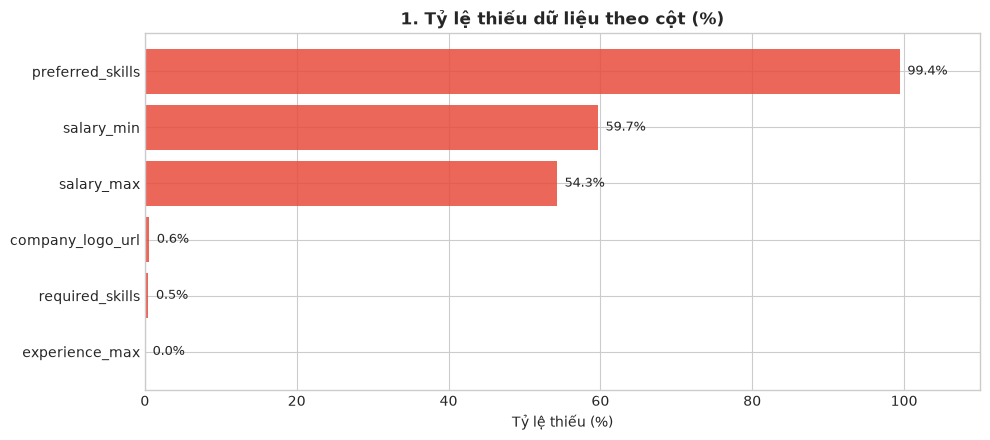

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

missing_plot_data = missing_df[missing_df['Số dòng thiếu'] > 0].sort_values(by='Tỷ lệ thiếu (%)', ascending=True)

plt.figure(figsize=(10, 4.5))
bars = plt.barh(missing_plot_data['Cột'], missing_plot_data['Tỷ lệ thiếu (%)'], color='#e74c3c', alpha=0.85)
plt.title('1. Tỷ lệ thiếu dữ liệu theo cột (%)', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ thiếu (%)')
for idx, val in enumerate(missing_plot_data['Tỷ lệ thiếu (%)']):
    plt.text(val + 1, idx, f"{val:.1f}%", va='center', fontsize=9)
plt.xlim(0, 110)
plt.tight_layout()
plt.show()


### 3.2. Cơ cấu Mô hình làm việc (Work Mode) & Hình thức (Employment Type)


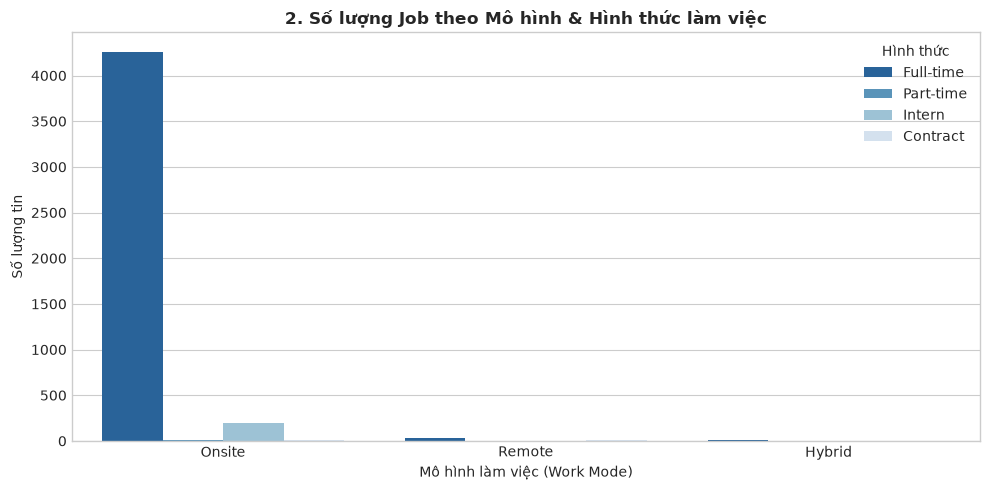

In [20]:
plt.figure(figsize=(10, 5))
sns.countplot(data=jobs, x='work_mode', hue='employment_type', palette='Blues_r')
plt.title('2. Số lượng Job theo Mô hình & Hình thức làm việc', fontsize=12, fontweight='bold')
plt.xlabel('Mô hình làm việc (Work Mode)')
plt.ylabel('Số lượng tin')
plt.legend(title='Hình thức')
plt.tight_layout()
plt.show()


### 3.3. Phân bố Số năm kinh nghiệm tối thiểu yêu cầu


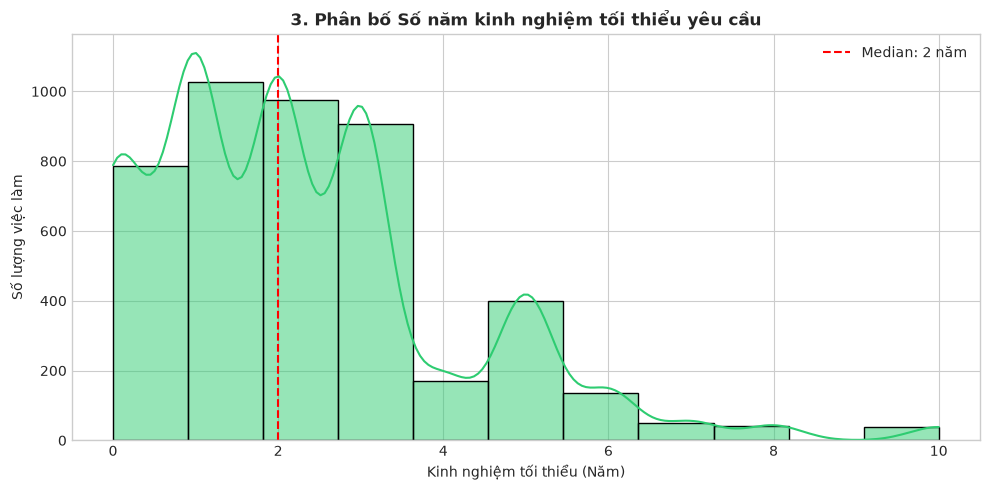

In [21]:
exp_clean = jobs['experience_min'].dropna()

plt.figure(figsize=(10, 5))
sns.histplot(exp_clean[exp_clean <= 10], bins=11, kde=True, color='#2ecc71')
plt.axvline(exp_clean.median(), color='red', linestyle='--', label=f"Median: {exp_clean.median():.0f} năm")
plt.title('3. Phân bố Số năm kinh nghiệm tối thiểu yêu cầu', fontsize=12, fontweight='bold')
plt.xlabel('Kinh nghiệm tối thiểu (Năm)')
plt.ylabel('Số lượng việc làm')
plt.legend()
plt.tight_layout()
plt.show()


### 3.4. Boxplot Phân bố Mức lương tối đa theo Thành phố (Triệu VNĐ)


C:\Users\Minh Doan\AppData\Local\Temp\ipykernel_4324\3703041375.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sal_df, x='city', y='salary_max_mil', palette='Spectral')


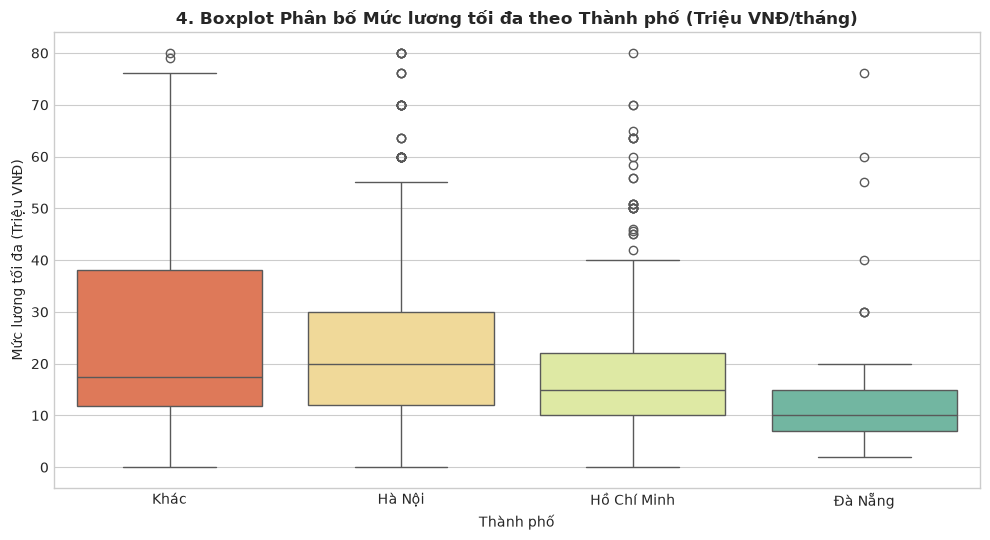

In [22]:
sal_df = jobs[jobs['salary_max'].notna() & (jobs['salary_max'] <= 80e6) & (jobs['salary_max'] > 0)].copy()
sal_df['salary_max_mil'] = sal_df['salary_max'] / 1e6

plt.figure(figsize=(10, 5.5))
sns.boxplot(data=sal_df, x='city', y='salary_max_mil', palette='Spectral')
plt.title('4. Boxplot Phân bố Mức lương tối đa theo Thành phố (Triệu VNĐ/tháng)', fontsize=12, fontweight='bold')
plt.xlabel('Thành phố')
plt.ylabel('Mức lương tối đa (Triệu VNĐ)')
plt.tight_layout()
plt.show()


### 3.5. Tỷ lệ Tin tuyển dụng còn hiệu lực (`is_active`)


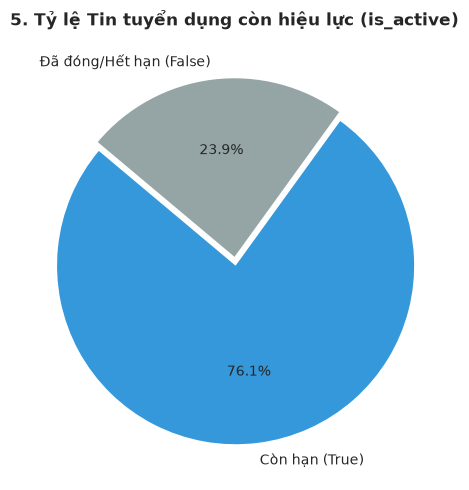

In [23]:
active_counts = jobs['is_active'].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(active_counts, labels=['Còn hạn (True)', 'Đã đóng/Hết hạn (False)'], autopct='%1.1f%%',
        startangle=140, colors=['#3498db', '#95a5a6'], explode=(0.05, 0))
plt.title('5. Tỷ lệ Tin tuyển dụng còn hiệu lực (is_active)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.6. Top 15 Kỹ năng công nghệ yêu cầu phổ biến nhất thị trường


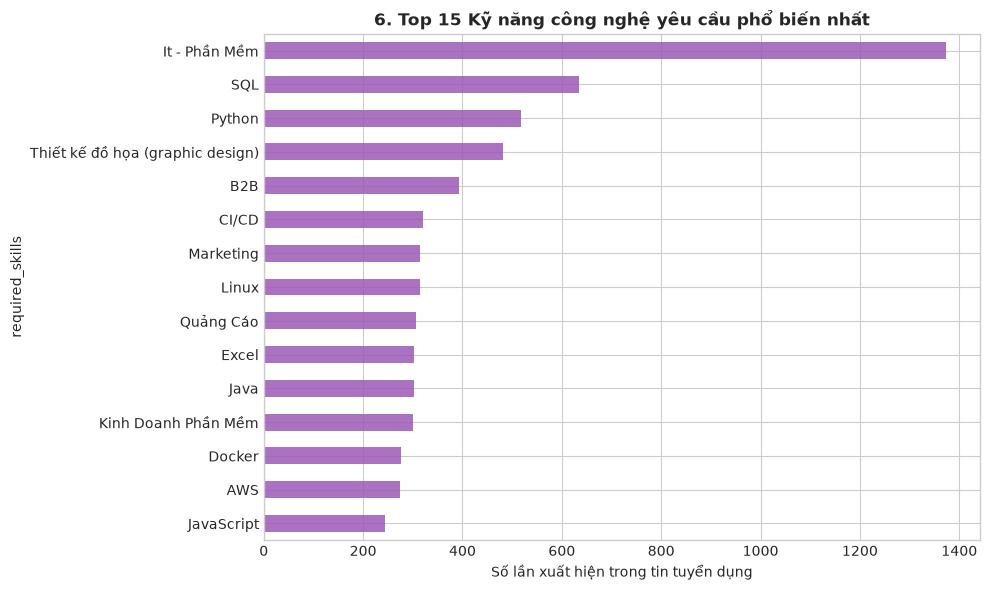

In [24]:
all_skills_series = jobs['required_skills'].dropna().str.split(',').explode().str.strip()
top15_skills = all_skills_series[all_skills_series != ''].value_counts().head(15)

plt.figure(figsize=(10, 6))
top15_skills.sort_values(ascending=True).plot(kind='barh', color='#9b59b6', alpha=0.85)
plt.title('6. Top 15 Kỹ năng công nghệ yêu cầu phổ biến nhất', fontsize=12, fontweight='bold')
plt.xlabel('Số lần xuất hiện trong tin tuyển dụng')
plt.tight_layout()
plt.show()


## 4. Chuẩn Hóa Kỹ Năng & Xây Dựng "Content Soup" (Feature Engineering)

### 1. Chuẩn hóa Kỹ năng (Skill Canonicalization)
Sử dụng bộ danh bạ quy chuẩn **`CANONICAL_SKILL_MAP`** để đồng nhất hóa cách viết (`ReactJS`/`React.js` -> `React`, `ML` -> `Machine Learning`).

### 2. Xây dựng "Content Soup" có gán trọng số
$$\text{Content Soup} = (\text{Title} \times 3) + (\text{Required Skills} \times 4) + (\text{Description} \times 1)$$


In [25]:
# 1. Danh mục chuẩn hóa kỹ năng công nghệ IT (Canonical Skill Map)
CANONICAL_SKILL_MAP = {
    'python': 'Python', 'java': 'Java', 'javascript': 'JavaScript', 'js': 'JavaScript',
    'typescript': 'TypeScript', 'ts': 'TypeScript', 'c++': 'C++', 'c#': 'C#',
    'php': 'PHP', 'golang': 'Golang', 'go': 'Golang', 'ruby': 'Ruby', 'rust': 'Rust',
    'react': 'React', 'reactjs': 'React', 'vue': 'Vue', 'vuejs': 'Vue', 'angular': 'Angular',
    'node': 'Node.js', 'nodejs': 'Node.js', 'spring boot': 'Spring Boot', 'springboot': 'Spring Boot',
    'laravel': 'Laravel', '.net': '.NET', 'dotnet': '.NET', 'sql': 'SQL', 'mysql': 'MySQL',
    'postgresql': 'PostgreSQL', 'mongodb': 'MongoDB', 'redis': 'Redis', 'kafka': 'Kafka',
    'docker': 'Docker', 'kubernetes': 'Kubernetes', 'k8s': 'Kubernetes', 'aws': 'AWS',
    'azure': 'Azure', 'gcp': 'GCP', 'ci/cd': 'CI/CD', 'git': 'Git', 'linux': 'Linux',
    'power bi': 'Power BI', 'tableau': 'Tableau', 'excel': 'Excel', 'spark': 'Spark',
    'machine learning': 'Machine Learning', 'ml': 'Machine Learning', 'ai': 'AI',
    'deep learning': 'Deep Learning', 'nlp': 'NLP', 'pytorch': 'PyTorch', 'tensorflow': 'TensorFlow'
}

def extract_skills_from_text(text):
    """Bóc tách kỹ năng công nghệ chuẩn hóa từ văn bản tự do (CV/Đoạn mô tả)."""
    text_lower = str(text).lower()
    detected = []
    seen = set()
    for key, val in CANONICAL_SKILL_MAP.items():
        if re.search(r'\b' + re.escape(key) + r'\b', text_lower):
            if val.lower() not in seen:
                seen.add(val.lower())
                detected.append(val)
    return detected

# 2. Xây dựng Content Soup gán trọng số
def build_content_soup(row):
    title = str(row.get('title', '')) if pd.notnull(row.get('title')) else ''
    skills = str(row.get('required_skills', '')) if pd.notnull(row.get('required_skills')) else ''
    desc = str(row.get('description_clean', '')) if pd.notnull(row.get('description_clean')) else ''
    soup = f"{title} {title} {title} {skills} {skills} {skills} {skills} {desc}"
    return soup.strip()

jobs['content_soup'] = jobs.apply(build_content_soup, axis=1)

print("=== MẪU CONTENT SOUP CỦA 2 CÔNG VIỆC ĐẦU TIÊN ===")
for idx, s in enumerate(jobs['content_soup'].head(2)):
    print(f"\n[Job {idx+1}] {jobs.iloc[idx]['title']}:")
    print(s[:250] + "...")


=== MẪU CONTENT SOUP CỦA 2 CÔNG VIỆC ĐẦU TIÊN ===

[Job 1] Kỹ Sư Hạ Tầng Công Nghệ Thông Tin:
Kỹ Sư Hạ Tầng Công Nghệ Thông Tin Kỹ Sư Hạ Tầng Công Nghệ Thông Tin Kỹ Sư Hạ Tầng Công Nghệ Thông Tin It - Phần Mềm, Sản Xuất, Tiếng trung giao tiếp thành thạo, Tiếng Trung Hsk 4, Linux It - Phần Mềm, Sản Xuất, Tiếng trung giao tiếp thành thạo, Tiếng...

[Job 2] Chuyên Viên BA Nghiệp Vụ:
Chuyên Viên BA Nghiệp Vụ Chuyên Viên BA Nghiệp Vụ Chuyên Viên BA Nghiệp Vụ Chuyên môn công nghệ thông tin khác, It - Phần Mềm, Y Tế, Dược Phẩm, SQL, Jira Chuyên môn công nghệ thông tin khác, It - Phần Mềm, Y Tế, Dược Phẩm, SQL, Jira Chuyên môn công n...


## 5. Vector Hóa Văn Bản (TF-IDF) & Phân Tích Tương Đồng Giữa Các Job

- Cấu hình `TfidfVectorizer` với `token_pattern=r"(?u)\b[a-zA-Z0-9_+#\.]+\b"` để **bảo tồn nguyên vẹn các ký tự đặc biệt IT** như `C++`, `C#`, `.NET`, `CI/CD`.
- Tính ma trận Cosine Similarity giữa các bài đăng và vẽ Heatmap tương đồng mẫu.


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import time

start_time = time.time()

# 1. Khởi tạo TF-IDF Vectorizer bảo toàn ký tự kỹ thuật
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b[a-zA-Z0-9_+#\.]+\b",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)
tfidf_matrix = tfidf.fit_transform(jobs['content_soup'])

elapsed = time.time() - start_time
print(f" Đã vector hóa thành công: {tfidf_matrix.shape[0]:,} jobs x {tfidf_matrix.shape[1]:,} features")
print(f" Thời gian thực thi TF-IDF: {elapsed:.2f} giây")


 Đã vector hóa thành công: 4,536 jobs x 10,000 features
 Thời gian thực thi TF-IDF: 1.81 giây


### Heatmap Cosine Similarity giữa các bài đăng mẫu (Job-to-Job)


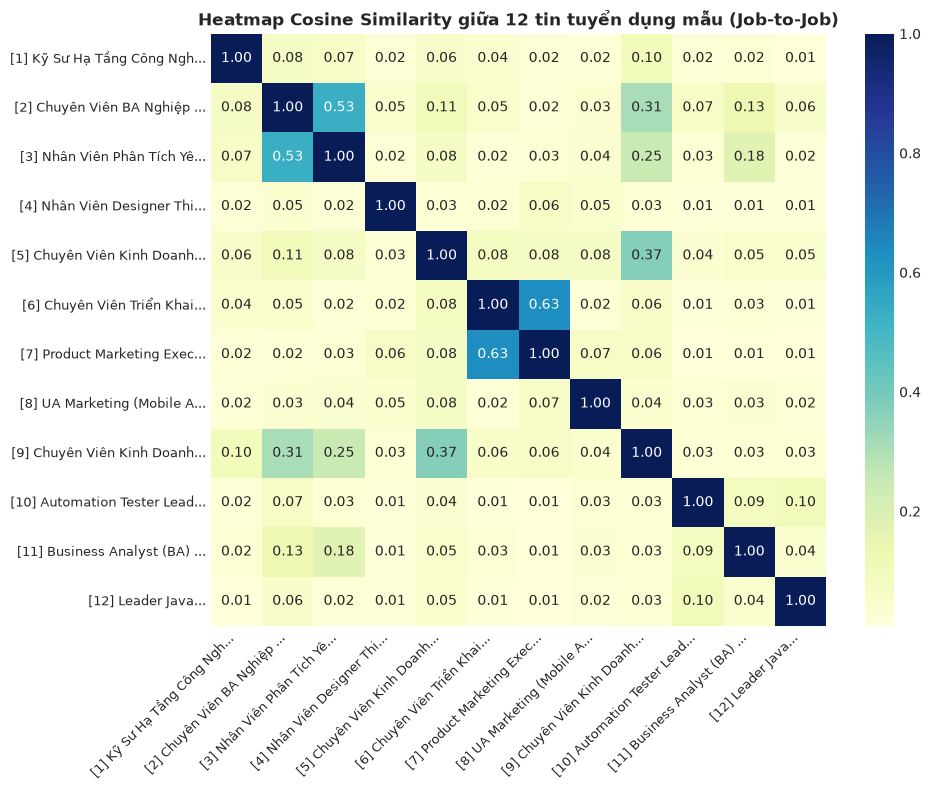

In [27]:
sample_submatrix = cosine_similarity(tfidf_matrix[:12], tfidf_matrix[:12])
job_short_titles = [f"[{i+1}] {t[:22]}..." for i, t in enumerate(jobs['title'].head(12))]

plt.figure(figsize=(10, 8))
sns.heatmap(sample_submatrix, annot=True, fmt=".2f", cmap='YlGnBu',
            xticklabels=job_short_titles, yticklabels=job_short_titles, cbar=True)
plt.title("Heatmap Cosine Similarity giữa 12 tin tuyển dụng mẫu (Job-to-Job)", fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


## 6. Thiết Kế Hệ Thống Chấm Điểm Đa Thành Phần (Composite Scoring Engine)

### Công thức điểm tổng hợp:
$$\text{Score}(j, u) = 0.40 S_{skills} + 0.30 S_{text} + 0.10 S_{experience} + 0.10 S_{location/work\ mode} + 0.10 S_{salary}$$

- **Dynamic Re-weighting:** Nếu bài đăng để lương *"Thỏa thuận"*, hệ thống tự động loại bỏ thành phần lương và chuẩn hóa lại 4 trọng số còn lại về $1.0$ ($w'_i = \frac{w_i}{\sum_{k \neq \text{sal}} w_k}$).
- Để code rõ ràng, các hàm tính toán ngắn gọn được nhóm lại, trong khi các hàm nghiệp vụ dài (`recommend_jobs`, `analyze_cv_fit_for_job`) được tách riêng thành từng cell.


### 6.1. Các hàm tính điểm thành phần chuẩn hóa [0, 1] & Cơ chế co giãn trọng số


In [28]:
def compute_skill_score(user_skills, job_required_skills, job_preferred_skills=None):
    """S_skills: Tỷ lệ khớp kỹ năng (80% required + 20% preferred)."""
    if not job_required_skills:
        return 0.5
    user_set = set(s.lower() for s in user_skills)
    req_set = set(s.lower() for s in job_required_skills)
    pref_set = set(s.lower() for s in job_preferred_skills) if job_preferred_skills else set()
    
    req_matched = len(user_set.intersection(req_set))
    s_req = req_matched / len(req_set) if req_set else 1.0
    
    if pref_set:
        pref_matched = len(user_set.intersection(pref_set))
        s_pref = pref_matched / len(pref_set) if pref_set else 0.0
        return round(0.8 * s_req + 0.2 * s_pref, 3)
    return round(s_req, 3)

def compute_exp_score(user_exp, job_min_exp, job_max_exp=None):
    """S_experience: Điểm phù hợp số năm kinh nghiệm."""
    if pd.isna(job_min_exp) or job_min_exp == 0:
        return 1.0
    diff = user_exp - job_min_exp
    if diff >= 0:
        if pd.notna(job_max_exp) and user_exp > job_max_exp + 3:
            return 0.85 # Hơi overqualified
        return 1.0
    elif diff >= -1.0:
        return 0.7  # Thiếu <= 1 năm kinh nghiệm: vẫn xem xét được
    elif diff >= -2.0:
        return 0.4
    else:
        return 0.1  # Thiếu quá nhiều năm kinh nghiệm

def compute_location_mode_score(user_city, user_modes, job_city, job_mode):
    """S_location/mode: Điểm kết hợp địa điểm và mô hình làm việc."""
    score_mode = 0.5
    score_city = 0.5
    job_mode_str = str(job_mode).lower()
    
    if isinstance(user_modes, str):
        user_modes = [user_modes]
    user_modes_lower = [m.lower() for m in user_modes] if user_modes else ['tất cả']
    
    if 'tất cả' in user_modes_lower or not user_modes:
        score_mode = 1.0
    elif any(m in job_mode_str for m in user_modes_lower):
        score_mode = 1.0
    elif 'remote' in job_mode_str:
        score_mode = 0.9  # Làm từ xa luôn linh hoạt
    elif 'hybrid' in job_mode_str and any('remote' in m for m in user_modes_lower):
        score_mode = 0.8
    else:
        score_mode = 0.2
        
    if user_city == 'Tất cả' or not user_city:
        score_city = 1.0
    elif str(job_city).lower() == str(user_city).lower():
        score_city = 1.0
    elif 'remote' in job_mode_str:
        score_city = 1.0
    else:
        score_city = 0.1
        
    return round(0.5 * score_city + 0.5 * score_mode, 3)

def compute_salary_score(user_min_salary, job_salary_min, job_salary_max):
    """S_salary: Trả về None nếu bài đăng không có số liệu lương."""
    if pd.isna(job_salary_max) and pd.isna(job_salary_min):
        return None
    max_sal = job_salary_max if pd.notna(job_salary_max) else job_salary_min
    if not user_min_salary or user_min_salary == 0:
        return 1.0
    if max_sal >= user_min_salary:
        return 1.0
    else:
        ratio = max_sal / user_min_salary
        return round(max(0.0, float(ratio)), 3)

def compute_composite_score(s_skills, s_text, s_exp, s_loc, s_sal, base_weights=None):
    """Tính điểm tổng hợp Score(j, u) và tự động chuẩn hóa lại trọng số khi thiếu lương."""
    if base_weights is None:
        base_weights = {
            'skills': 0.40,
            'text': 0.30,
            'exp': 0.10,
            'loc': 0.10,
            'sal': 0.10
        }
    weights = base_weights.copy()
    scores = {
        'skills': s_skills,
        'text': s_text,
        'exp': s_exp,
        'loc': s_loc,
        'sal': s_sal
    }
    if s_sal is None:
        del weights['sal']
        del scores['sal']
        total_w = sum(weights.values())
        weights = {k: v / total_w for k, v in weights.items()}
        
    total_score = sum(weights[k] * scores[k] for k in weights)
    return round(total_score, 4), weights

print(" Đã khởi tạo các hàm tính điểm thành phần và cơ chế co giãn trọng số!")


 Đã khởi tạo các hàm tính điểm thành phần và cơ chế co giãn trọng số!


### 6.2. Các hàm hỗ trợ hiển thị & Sinh lời giải thích (Rationale Generator)


In [29]:
def generate_rationale(matched_skills, missing_skills, user_exp, job_min_exp, job_mode, is_salary_fit):
    """Sinh câu giải thích gợi ý trực quan."""
    reasons = []
    total_skills = len(matched_skills) + len(missing_skills)
    if total_skills > 0:
        matched_str = ', '.join(matched_skills[:3]) if matched_skills else 'Chưa trùng trực tiếp'
        reasons.append(f"Khớp {len(matched_skills)}/{total_skills} kỹ năng ({matched_str})")
    if pd.isna(job_min_exp) or job_min_exp == 0:
        reasons.append("Không đòi hỏi số năm kinh nghiệm")
    elif user_exp >= job_min_exp:
        reasons.append(f"Kinh nghiệm phù hợp ({user_exp:.0f} năm >= yêu cầu {job_min_exp:.0f} năm)")
    else:
        reasons.append(f"Yêu cầu {job_min_exp:.0f} năm (bạn có {user_exp:.0f} năm)")
    reasons.append(f"Hình thức {job_mode}")
    if is_salary_fit is True:
        reasons.append("Đạt kỳ vọng lương")
    elif is_salary_fit is None:
        reasons.append("Lương thỏa thuận")
    else:
        reasons.append("Thấp hơn kỳ vọng lương")
    return "; ".join(reasons)

def format_salary_display(s_min, s_max):
    """Định dạng hiển thị mức lương trực quan."""
    if pd.notnull(s_min) and pd.notnull(s_max):
        if s_min == s_max:
            return f"{s_min/1e6:.0f} tr"
        return f"{s_min/1e6:.0f} - {s_max/1e6:.0f} tr"
    elif pd.notnull(s_max):
        return f"Lên đến {s_max/1e6:.0f} tr"
    elif pd.notnull(s_min):
        return f"Từ {s_min/1e6:.0f} tr"
    return "Thoả thuận"

print(" Đã khởi tạo các hàm sinh lời giải thích (Rationale) và định dạng lương!")


 Đã khởi tạo các hàm sinh lời giải thích (Rationale) và định dạng lương!


### 6.3. Hàm Gợi ý Việc làm Toàn diện (`recommend_jobs`)


In [30]:
def recommend_jobs(
    target_title="",
    cv_text="",
    skills=None,
    user_exp=1.0,
    preferred_city="Tất cả",
    preferred_work_modes=None,
    min_salary=None,
    top_n=10
):
    """
    Hàm gợi ý việc làm toàn diện kết hợp:
    Vị trí + Kỹ năng chọn tay + Đoạn văn bản CV + Kinh nghiệm + Địa điểm + Hình thức + Lương mong muốn.
    """
    manual_skills = skills or []
    extracted_skills = extract_skills_from_text(cv_text) if cv_text else []
    all_user_skills = list(dict.fromkeys(manual_skills + extracted_skills))
    
    parts = []
    if target_title:
        parts.extend([target_title, target_title, target_title])
    if all_user_skills:
        s_str = " ".join(all_user_skills)
        parts.extend([s_str, s_str, s_str, s_str])
    if cv_text:
        parts.append(cv_text)
    profile_soup = " ".join(parts).strip()
    if not profile_soup:
        print(" Vui lòng cung cấp ít nhất một thông tin: Vị trí (target_title), Kỹ năng (skills), hoặc Văn bản CV (cv_text).")
        return pd.DataFrame()
        
    profile_vec = tfidf.transform([profile_soup])
    text_similarities = cosine_similarity(profile_vec, tfidf_matrix).flatten()
    
    candidates = []
    for idx, row in jobs.iterrows():
        # Bỏ qua tin không còn hoạt động
        if 'is_active' in row and not row['is_active']:
            continue
            
        req_skills = [s.strip() for s in str(row.get('required_skills', '')).split(',') if s.strip()]
        pref_skills = [s.strip() for s in str(row.get('preferred_skills', '')).split(',') if s.strip()]
        
        s_skills = compute_skill_score(all_user_skills, req_skills, pref_skills)
        s_text = round(float(text_similarities[idx]), 4)
        s_exp = compute_exp_score(user_exp, row.get('experience_min'), row.get('experience_max'))
        s_loc = compute_location_mode_score(preferred_city, preferred_work_modes, row.get('city'), row.get('work_mode'))
        s_sal = compute_salary_score(min_salary, row.get('salary_min'), row.get('salary_max'))
        
        composite_score, _ = compute_composite_score(s_skills, s_text, s_exp, s_loc, s_sal)
        
        user_skills_lower = set(s.lower() for s in all_user_skills)
        matched = [s for s in req_skills if s.lower() in user_skills_lower]
        missing = [s for s in req_skills if s.lower() not in user_skills_lower]
        
        is_sal_fit = True if s_sal == 1.0 else (None if s_sal is None else False)
        rationale = generate_rationale(matched, missing, user_exp, row.get('experience_min'), row.get('work_mode', 'Onsite'), is_sal_fit)
        
        candidates.append({
            'job_id': row.get('job_id'),
            'Tiêu đề': row.get('title'),
            'Công ty': row.get('company_name'),
            'Tổng điểm (%)': round(composite_score * 100, 1),
            'Điểm kỹ năng (%)': round(s_skills * 100, 1),
            'Điểm văn bản (%)': round(s_text * 100, 1),
            'Điểm kinh nghiệm (%)': round(s_exp * 100, 1),
            'Điểm vị trí/hình thức (%)': round(s_loc * 100, 1),
            'Lời giải thích': rationale,
            'Kinh nghiệm yêu cầu': f"{row['experience_min']} năm" if pd.notnull(row.get('experience_min')) else 'Không yêu cầu',
            'Hình thức': row.get('work_mode', 'Onsite'),
            'Thành phố': row.get('city', 'Không rõ'),
            'Mức lương': format_salary_display(row.get('salary_min'), row.get('salary_max')),
            'job_url': row.get('job_url', ''),
            'company_logo_url': row.get('company_logo_url', '')
        })
        
    df_res = pd.DataFrame(candidates).sort_values(by='Tổng điểm (%)', ascending=False)
    return df_res.head(top_n)

print(" Đã khởi tạo hàm recommend_jobs hoàn chỉnh!")


 Đã khởi tạo hàm recommend_jobs hoàn chỉnh!


### 6.4. Hàm Báo Cáo Đánh Giá Độ Phù Hợp 1:1 (`analyze_cv_fit_for_job`)


In [31]:
def analyze_cv_fit_for_job(job_identifier, cv_text="", skills=None, user_exp=1.0):
    """Báo cáo đánh giá chi tiết độ phù hợp 1:1 giữa hồ sơ ứng viên và một công việc cụ thể."""
    if isinstance(job_identifier, (int, np.integer)):
        idx = int(job_identifier)
    elif isinstance(job_identifier, str):
        match = jobs[jobs['job_id'] == job_identifier]
        if match.empty:
            match = jobs[jobs['title'].str.contains(job_identifier, case=False, na=False, regex=False)]
        if match.empty:
            return f" Không tìm thấy công việc: {job_identifier}"
        idx = match.index[0]
        
    job = jobs.iloc[idx]
    manual_skills = skills or []
    extracted_skills = extract_skills_from_text(cv_text) if cv_text else []
    all_user_skills = list(dict.fromkeys(manual_skills + extracted_skills))
    user_skills_lower = set(s.lower() for s in all_user_skills)
    
    input_text = f"{' '.join(all_user_skills)} {cv_text}".strip()
    user_vec = tfidf.transform([input_text])
    job_vec = tfidf.transform([job['content_soup']])
    sim_score = cosine_similarity(user_vec, job_vec)[0][0]
    
    job_skills = [s.strip() for s in str(job.get('required_skills', '')).split(',') if s.strip()]
    matched = [s for s in job_skills if s.lower() in user_skills_lower]
    missing = [s for s in job_skills if s.lower() not in user_skills_lower]
    
    exp_required = job.get('experience_min') if pd.notnull(job.get('experience_min')) else 0.0
    exp_status = f" Đạt yêu cầu ({user_exp} năm >= {exp_required} năm)" if user_exp >= exp_required else f" Chưa đủ kinh nghiệm ({user_exp} năm < yêu cầu {exp_required} năm)"
    coverage_pct = round(len(matched) / len(job_skills) * 100, 1) if job_skills else 100.0
    
    report = f"""================================================================================
 BÁO CÁO ĐÁNH GIÁ ĐỘ PHÙ HỢP HỒ SƠ VỚI CÔNG VIỆC (1:1 FIT REPORT)
================================================================================
Công việc mục tiêu: {job['title']}
Công ty:             {job['company_name']}
Địa điểm:            {job.get('city', 'Không rõ')} ({job.get('work_mode', 'Tại văn phòng')})
Mức lương:           {format_salary_display(job.get('salary_min'), job.get('salary_max'))}

--- 1. ĐIỂM SỐ TỔNG QUAN ---
• Điểm tương đồng nội dung (Text Similarity):    {sim_score * 100:.1f}%
• Tỷ lệ đáp ứng kỹ năng (Skill Coverage):         {coverage_pct}% ({len(matched)}/{len(job_skills)} kỹ năng)
• Đánh giá số năm kinh nghiệm:                   {exp_status}

--- 2. CHI TIẾT KỸ NĂNG ---
 Kỹ năng bạn đã có ({len(matched)}):
   {', '.join(matched) if matched else 'Chưa trùng trực tiếp kỹ năng công nghệ'}
 Kỹ năng còn thiếu mà công ty yêu cầu ({len(missing)}):
   {', '.join(missing) if missing else 'Tuyệt vời! Bạn đáp ứng đầy đủ tất cả kỹ năng'}
================================================================================"""
    return report

print(" Đã khởi tạo hàm analyze_cv_fit_for_job hoàn chỉnh!")


 Đã khởi tạo hàm analyze_cv_fit_for_job hoàn chỉnh!


## 7. Thử Nghiệm Thực Tế Với Các Kịch Bản Đa Dạng (Case Studies)

Thực nghiệm hệ thống với 4 kịch bản ứng viên:
- **Case 1 (Theo đúng tiêu chuẩn thiết kế mục tiêu)**:
  * Kỹ năng: `Python`, `SQL`, `Machine Learning`
  * Kinh nghiệm: `1.0` năm
  * Địa điểm mong muốn: `Hà Nội`
  * Hình thức làm việc: `Remote` hoặc `Hybrid`
  * Mức lương kỳ vọng: từ `20,000,000` VNĐ (>= 20 triệu)
  * -> Trả về Top 10 kèm Tổng điểm, các điểm thành phần và Lời giải thích trực quan.
- **Case 2**: Ứng viên dán văn bản CV (DevOps/Cloud Microservices tại TP.HCM).
- **Case 3**: Ứng viên Data Analyst kết hợp dán CV và lọc lương tối thiểu.
- **Case 4**: Báo cáo đánh giá chi tiết 1:1 (Fit Report) giữa CV và công việc Top 1.


In [32]:
# --- CASE 1: KỊCH BẢN THIẾT KẾ CHUẨN (Python, SQL, Machine Learning | 1 năm | Hà Nội | Remote/Hybrid | Lương >= 20tr) ---
print("=== CASE 1: ỨNG VIÊN PYTHON, SQL, MACHINE LEARNING (Hà Nội, Remote/Hybrid, Lương >= 20tr) ===")
res1 = recommend_jobs(
    target_title="Python Developer Machine Learning",
    skills=["Python", "SQL", "Machine Learning"],
    user_exp=1.0,
    preferred_city="Hà Nội",
    preferred_work_modes=["Remote", "Hybrid"],
    min_salary=20000000,
    top_n=10
)
display(res1[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Điểm kinh nghiệm (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 2: ỨNG VIÊN DÁN VĂN BẢN CV (DevOps / Microservices, TP.HCM) ---
print("\n=== CASE 2: ỨNG VIÊN DÁN VĂN BẢN CV (DevOps / Microservices, Hồ Chí Minh) ===")
cv_devops = """
Kỹ sư DevOps với 3 năm kinh nghiệm làm việc với hệ thống Microservices.
Thành thạo Docker, Kubernetes (K8s), xây dựng CI/CD pipeline tự động hóa với GitLab CI và Jenkins.
Kinh nghiệm quản trị hệ thống Linux, triển khai hạ tầng đám mây trên AWS (EC2, S3, RDS, EKS).
"""
res2 = recommend_jobs(
    target_title="DevOps Engineer",
    cv_text=cv_devops,
    user_exp=3.0,
    preferred_city="Hồ Chí Minh",
    top_n=5
)
display(res2[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 3: KẾT HỢP CV + KỸ NĂNG BỔ SUNG + LỌC LƯƠNG TỐI THIỂU >= 15 TRIỆU ---
print("\n=== CASE 3: KẾT HỢP CV + KỸ NĂNG BỔ SUNG + LỌC LƯƠNG >= 15 TRIỆU ===")
cv_da = """
Chuyên viên phân tích dữ liệu với 1 năm kinh nghiệm.
Sử dụng thành thạo SQL để truy vấn và xử lý dữ liệu lớn, thành thạo Excel và Power BI xây dựng Dashboard quản trị kinh doanh.
"""
res3 = recommend_jobs(
    target_title="Data Analyst",
    cv_text=cv_da,
    skills=["Python", "Tableau"],
    user_exp=1.0,
    preferred_city="Tất cả",
    min_salary=15000000,
    top_n=5
)
display(res3[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 4: SO KHỚP CHUYÊN SÂU 1:1 GIỮA CV VÀ CÔNG VIỆC TOP 1 ---
top1_job = res2.iloc[0]['Tiêu đề']
rep4 = analyze_cv_fit_for_job(job_identifier=top1_job, cv_text=cv_devops, user_exp=3.0)
print("\n" + rep4)


=== CASE 1: ỨNG VIÊN PYTHON, SQL, MACHINE LEARNING (Hà Nội, Remote/Hybrid, Lương >= 20tr) ===


,Tiêu đề,Công ty,Tổng điểm (%),Điểm kỹ năng (%),Điểm văn bản (%),Điểm kinh nghiệm (%),Lời giải thích,Mức lương
1559,AI Engineer,IOTLINK,58.2,80.0,29.6,100.0,Khớp 1/1 kỹ năng (Python); Kinh nghiệm phù hợp...,Thoả thuận
971,AI Engineer Từ 3 Năm Kinh Nghiệm,Digital Innovation,53.9,80.0,6.5,40.0,Khớp 1/1 kỹ năng (Python); Yêu cầu 3 năm (bạn ...,Lên đến 30 tr
3348,Data Business Analytics (Oracle),viễn thông FPT,53.2,80.0,3.9,40.0,Khớp 1/1 kỹ năng (SQL); Yêu cầu 3 năm (bạn có ...,30 - 50 tr
3025,Kỹ Sư Quản Lý Chất Lượng,VIETTEL DIGITAL SERVICES CORPORATION - BRANCH ...,51.3,80.0,4.0,70.0,Khớp 1/1 kỹ năng (SQL); Yêu cầu 2 năm (bạn có ...,Thoả thuận
128,Trưởng Nhóm Phân Tích Dữ Liệu (Data Analyst),Alphaway Technology,49.9,53.3,18.6,70.0,"Khớp 2/3 kỹ năng (Python, SQL); Yêu cầu 2 năm ...",Lên đến 38 tr
2945,Trưởng Nhóm Nghiên Cứu AI,Tổng Công Ty Bưu Điện Việt Nam - VIETNAMPOST,46.8,32.0,36.8,70.0,"Khớp 2/5 kỹ năng (Machine Learning, Python); Y...",35 - 80 tr
2298,Kỹ Sư Tự Động Hóa - Lập Trình Machine Vision,RTC TECHNOLOGY,45.1,40.0,25.3,100.0,Khớp 1/2 kỹ năng (Python); Kinh nghiệm phù hợp...,15 - 25 tr
1366,Data Scientist,Giải pháp Thanh toán Việt Nam (VNPAY),44.9,26.7,45.7,100.0,"Khớp 2/6 kỹ năng (Python, SQL); Kinh nghiệm ph...",Thoả thuận
1481,Engineer/Senior Engineer Of Artificial Intelli...,Hoya Glass Disk,44.1,26.7,43.4,100.0,"Khớp 2/6 kỹ năng (Machine Learning, Python); K...",Thoả thuận
623,"AI Engineer (NLP, LLM, AI Agent)",CÔNG NGHỆ SAVA META,42.6,40.0,12.1,70.0,Khớp 1/2 kỹ năng (Python); Yêu cầu 2 năm (bạn ...,Lên đến 30 tr



=== CASE 2: ỨNG VIÊN DÁN VĂN BẢN CV (DevOps / Microservices, Hồ Chí Minh) ===


,Tiêu đề,Công ty,Tổng điểm (%),Điểm kỹ năng (%),Điểm văn bản (%),Lời giải thích,Mức lương
136,DevOps Engineer,Apero Technologies Group,65.3,50.0,66.1,"Khớp 5/8 kỹ năng (Docker, Kubernetes, AWS); Ki...",20 - 45 tr
30,Chuyên viên cao cấp Vận hành hệ thống,AEON Finance,63.0,64.0,52.1,"Khớp 4/5 kỹ năng (Linux, Docker, Kubernetes); ...",Thoả thuận
2460,DevOps (InternalLead),Synodus,62.2,53.3,51.3,"Khớp 4/6 kỹ năng (Docker, Kubernetes, CI/CD); ...",Lên đến 45 tr
487,DevOps Engineer (Lead),CÔNG NGHỆ ALPHAWAY,60.6,45.7,56.2,"Khớp 4/7 kỹ năng (Docker, AWS, CI/CD); Kinh ng...",30 - 50 tr
3416,Nhân Viên Kỹ Thuật Phần Cứng CNTT,ĐẦU TƯ THƯƠNG MẠI HÀ CƯỜNG,60.1,80.0,8.8,Khớp 1/1 kỹ năng (Linux); Kinh nghiệm phù hợp ...,12 tr



=== CASE 3: KẾT HỢP CV + KỸ NĂNG BỔ SUNG + LỌC LƯƠNG >= 15 TRIỆU ===


,Tiêu đề,Công ty,Tổng điểm (%),Điểm kỹ năng (%),Điểm văn bản (%),Lời giải thích,Mức lương
1348,Data Analyst (Lead),Giải pháp Phân tích dữ liệu Insight Data,77.1,80.0,58.0,"Khớp 3/3 kỹ năng (SQL, Power BI, Excel); Kinh ...",Thoả thuận
1509,Trưởng Nhóm Data Analyst,HỆ THỐNG Y TẾ MEVIS HEALTHCARE,76.0,80.0,66.6,"Khớp 5/5 kỹ năng (Python, SQL, Power BI); Yêu ...",20 - 30 tr
128,Trưởng Nhóm Phân Tích Dữ Liệu (Data Analyst),Alphaway Technology,74.3,80.0,51.1,"Khớp 3/3 kỹ năng (Python, SQL, Power BI); Yêu ...",Lên đến 38 tr
1182,Data Analyst (Mảng Tài Chính),GALAXY DEBT TRADING COMPANY LIMITED,74.0,53.3,75.5,"Khớp 4/6 kỹ năng (Python, SQL, Power BI); Kinh...",15 tr
3093,Data Analyst,Vietnam Concentrix Services,71.1,80.0,39.9,"Khớp 3/3 kỹ năng (SQL, Power BI, Excel); Kinh ...",Thoả thuận



 BÁO CÁO ĐÁNH GIÁ ĐỘ PHÙ HỢP HỒ SƠ VỚI CÔNG VIỆC (1:1 FIT REPORT)
Công việc mục tiêu: DevOps Engineer
Công ty:             9Pay
Địa điểm:            Hà Nội (Onsite)
Mức lương:           Thoả thuận

--- 1. ĐIỂM SỐ TỔNG QUAN ---
• Điểm tương đồng nội dung (Text Similarity):    48.3%
• Tỷ lệ đáp ứng kỹ năng (Skill Coverage):         50.0% (5/10 kỹ năng)
• Đánh giá số năm kinh nghiệm:                    Đạt yêu cầu (3.0 năm >= 3.0 năm)

--- 2. CHI TIẾT KỸ NĂNG ---
 Kỹ năng bạn đã có (5):
   Docker, Kubernetes, AWS, CI/CD, Linux
 Kỹ năng còn thiếu mà công ty yêu cầu (5):
   Devops Engineer, It - Phần Mềm, Điện toán đám mây (cloud), Python, Git


## 8. Chẩn Đoán Phân Bố Điểm Số Recommender (Score Distribution Diagnostic)

Kiểm tra phân bố phổ điểm gợi ý trên tập mẫu rộng (Top 250 việc làm) để đảm bảo:
- Hệ thống **không** gán các điểm số xấp xỉ ngang nhau cho mọi công việc (tránh hiện tượng phân cụm điểm số).
- Có sự phân hóa rõ rệt: Các công việc top đầu đạt điểm cao vượt trội nhờ đáp ứng đồng thời cả kỹ năng, kinh nghiệm và văn bản.


### 8.1. Phân bố Tổng điểm Composite Score (Top 250 Jobs)


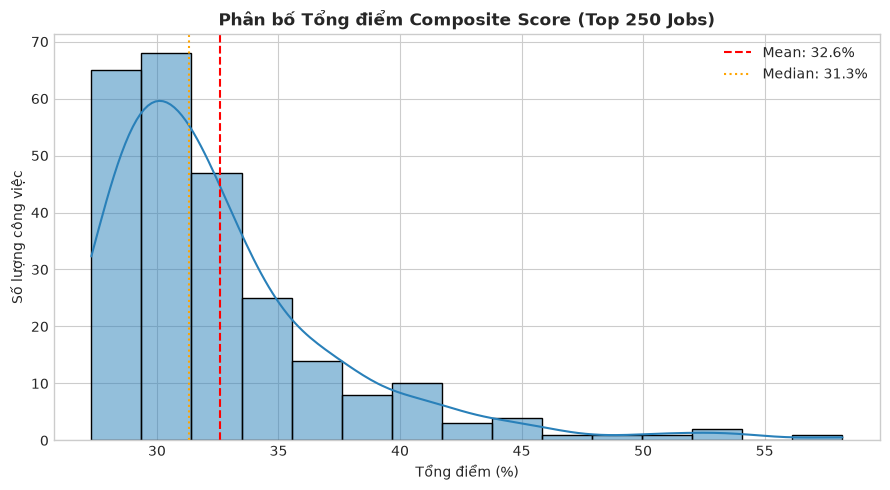

=== THỐNG KÊ MÔ TẢ ĐIỂM SỐ GỢI Ý ===


count    250.00
mean      32.60
std        4.96
min       27.30
25%       29.30
50%       31.30
75%       34.28
max       58.20
Name: Tổng điểm (%), dtype: float64

In [33]:
# Lấy phân bố điểm gợi ý của 250 việc làm hàng đầu từ Case 1
diagnostic_df = recommend_jobs(
    target_title="Python Developer Machine Learning",
    skills=["Python", "SQL", "Machine Learning"],
    user_exp=1.0,
    preferred_city="Hà Nội",
    preferred_work_modes=["Remote", "Hybrid"],
    top_n=250
)

plt.figure(figsize=(9, 5))
sns.histplot(diagnostic_df['Tổng điểm (%)'], bins=15, kde=True, color='#2980b9')
plt.axvline(diagnostic_df['Tổng điểm (%)'].mean(), color='red', linestyle='--', label=f"Mean: {diagnostic_df['Tổng điểm (%)'].mean():.1f}%")
plt.axvline(diagnostic_df['Tổng điểm (%)'].median(), color='orange', linestyle=':', label=f"Median: {diagnostic_df['Tổng điểm (%)'].median():.1f}%")
plt.title("Phân bố Tổng điểm Composite Score (Top 250 Jobs)", fontsize=12, fontweight='bold')
plt.xlabel("Tổng điểm (%)")
plt.ylabel("Số lượng công việc")
plt.legend()
plt.tight_layout()
plt.show()

print("=== THỐNG KÊ MÔ TẢ ĐIỂM SỐ GỢI Ý ===")
display(diagnostic_df['Tổng điểm (%)'].describe().round(2))


### 8.2. Điểm trung bình các thành phần trong Top 10 Gợi ý


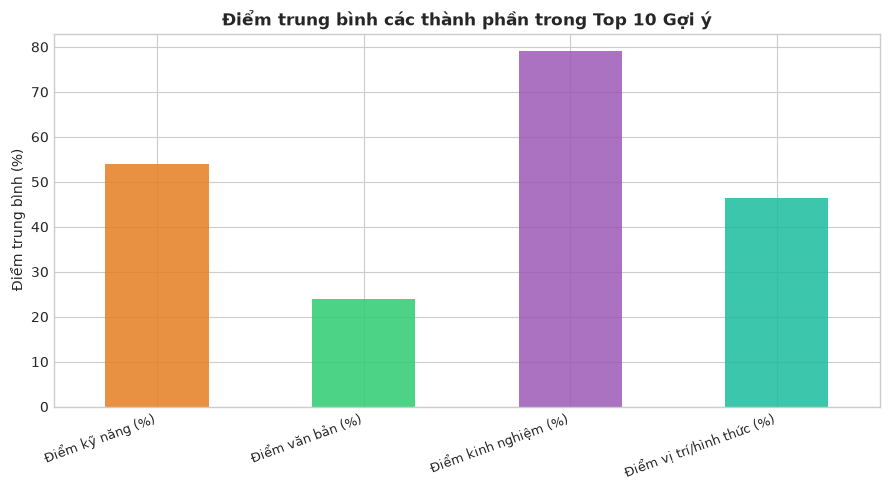

In [34]:
plt.figure(figsize=(9, 5))
top10_comp = diagnostic_df.head(10)[['Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Điểm kinh nghiệm (%)', 'Điểm vị trí/hình thức (%)']].mean()
top10_comp.plot(kind='bar', color=['#e67e22', '#2ecc71', '#9b59b6', '#1abc9c'], alpha=0.85)
plt.title("Điểm trung bình các thành phần trong Top 10 Gợi ý", fontsize=12, fontweight='bold')
plt.ylabel("Điểm trung bình (%)")
plt.xticks(rotation=20, ha='right', fontsize=9)
plt.tight_layout()
plt.show()


## 9. Đánh Giá & Đo Lường Hiệu Năng Hệ Thống Gợi Ý (Evaluation Metrics for CBF)

Đối với hệ thống gợi ý Content-Based khi chưa có log tương tác người dùng thực tế (Clicks/Applies), ta đánh giá khách quan qua **6 chỉ số chuẩn của RecSys** trên tập **25 Benchmark Test Profiles** đại diện cho 5 phân hệ IT chính:

1. **Domain Precision@5**: Tỷ lệ công việc trong Top 5 thuộc đúng phân hệ chuyên môn mục tiêu của ứng viên.
2. **Ranking Quality (NDCG@5)**: Đánh giá chất lượng xếp hạng (các công việc chuẩn phân hệ có được ưu tiên đưa lên vị trí Top 1, Top 2 hay không):
   $$\text{DCG@K} = \sum_{i=1}^{K} \frac{rel_i}{\log_2(i + 1)}, \quad \text{NDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}}$$
3. **Intra-List Diversity (ILD@5)**: Đo lường độ đa dạng bên trong danh sách gợi ý qua khoảng cách Cosine Distance:
   $$\text{ILD@K} = \frac{2}{K(K-1)} \sum_{i=1}^{K} \sum_{j=i+1}^{K} (1 - \text{CosineSimilarity}(\vec{v}_i, \vec{v}_j))$$
4. **Skill Coverage Rate (SCR@5)**: Tỷ lệ phần trăm các kỹ năng công việc yêu cầu mà ứng viên thực sự đáp ứng được trong Top 5 gợi ý.
5. **Catalog Coverage**: Tỷ lệ phần trăm số lượng tin việc làm trong kho (4,536 jobs) được hệ thống bao phủ khi quét qua 25 profiles.
6. **Cosine Similarity Distribution**: Phổ điểm tương đồng Cosine trung bình.


In [35]:
# 1. Khởi tạo tập Benchmark Test Profiles đại diện cho 5 phân hệ IT chính (25 profiles)
test_benchmark_profiles = [
    # Phân hệ Backend (5 profiles)
    {"domain": "Backend", "title": "Backend Python Developer", "skills": ["Python", "Django", "FastAPI", "PostgreSQL", "Docker", "Redis"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Backend", "title": "Java Spring Boot Engineer", "skills": ["Java", "Spring Boot", "MySQL", "Microservices", "Kafka"], "exp": 3.0, "city": "Hồ Chí Minh"},
    {"domain": "Backend", "title": "Node.js Backend Developer", "skills": ["Node.js", "Express", "MongoDB", "TypeScript", "Redis"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Backend", "title": ".NET Software Engineer", "skills": [".NET", "C#", "SQL Server", "Entity Framework"], "exp": 3.0, "city": "Đà Nẵng"},
    {"domain": "Backend", "title": "Golang Backend Engineer", "skills": ["Golang", "gRPC", "Docker", "Kubernetes", "PostgreSQL"], "exp": 2.5, "city": "Hồ Chí Minh"},
    
    # Phân hệ Frontend & Mobile (5 profiles)
    {"domain": "Frontend/Mobile", "title": "Frontend React Developer", "skills": ["React", "JavaScript", "TypeScript", "HTML5", "CSS3", "Redux"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Frontend/Mobile", "title": "Vue.js Frontend Engineer", "skills": ["Vue", "Nuxt.js", "JavaScript", "Tailwind CSS"], "exp": 1.5, "city": "Hồ Chí Minh"},
    {"domain": "Frontend/Mobile", "title": "Mobile Flutter Developer", "skills": ["Flutter", "Dart", "Firebase", "RESTful API"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Frontend/Mobile", "title": "iOS Swift Developer", "skills": ["iOS", "Swift", "Xcode", "Objective-C"], "exp": 3.0, "city": "Hà Nội"},
    {"domain": "Frontend/Mobile", "title": "Android Kotlin Developer", "skills": ["Android", "Kotlin", "Java", "Coroutines"], "exp": 2.0, "city": "Hồ Chí Minh"},
    
    # Phân hệ Data & AI (5 profiles)
    {"domain": "Data/AI", "title": "Data Analyst", "skills": ["SQL", "Python", "Power BI", "Tableau", "Excel"], "exp": 1.5, "city": "Hà Nội"},
    {"domain": "Data/AI", "title": "Data Engineer", "skills": ["Python", "SQL", "Spark", "Kafka", "Hadoop", "Airflow"], "exp": 3.0, "city": "Hồ Chí Minh"},
    {"domain": "Data/AI", "title": "Machine Learning Engineer", "skills": ["Python", "PyTorch", "TensorFlow", "Scikit-Learn", "Docker", "MLOps"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Data/AI", "title": "AI NLP Engineer", "skills": ["Python", "NLP", "LLM", "Hugging Face", "LangChain"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Data/AI", "title": "BI Developer", "skills": ["Power BI", "DAX", "SQL Server", "ETL", "Data Warehouse"], "exp": 2.5, "city": "Hồ Chí Minh"},
    
    # Phân hệ DevOps & Cloud & Security (5 profiles)
    {"domain": "DevOps/Cloud", "title": "DevOps Engineer", "skills": ["Docker", "Kubernetes", "CI/CD", "AWS", "Terraform", "Linux"], "exp": 3.0, "city": "Hà Nội"},
    {"domain": "DevOps/Cloud", "title": "Cloud Solutions Architect", "skills": ["AWS", "Azure", "GCP", "Microservices", "Docker"], "exp": 4.0, "city": "Hồ Chí Minh"},
    {"domain": "DevOps/Cloud", "title": "Site Reliability Engineer (SRE)", "skills": ["Linux", "Python", "Prometheus", "Grafana", "Kubernetes"], "exp": 3.0, "city": "Tất cả"},
    {"domain": "DevOps/Cloud", "title": "Cyber Security Specialist", "skills": ["Network", "Security", "SOC", "Firewall", "Linux"], "exp": 2.5, "city": "Hà Nội"},
    {"domain": "DevOps/Cloud", "title": "System Administrator", "skills": ["Linux", "Windows Server", "VMware", "Bash", "Network"], "exp": 2.0, "city": "Hồ Chí Minh"},
    
    # Phân hệ QA & QC & Testing (5 profiles)
    {"domain": "QA/QC", "title": "QA Automation Engineer", "skills": ["Selenium", "Python", "Java", "Postman", "CI/CD", "Git"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "QA/QC", "title": "Manual QC Tester", "skills": ["Test Case", "Jira", "SQL", "Bug Tracking", "API Testing"], "exp": 1.5, "city": "Hồ Chí Minh"},
    {"domain": "QA/QC", "title": "Software Test Engineer", "skills": ["Postman", "Jmeter", "Performance Testing", "SQL"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "QA/QC", "title": "Lead QA Engineer", "skills": ["Automation Test", "Appium", "Selenium", "Management"], "exp": 4.0, "city": "Hà Nội"},
    {"domain": "QA/QC", "title": "QC Specialist Web/App", "skills": ["Functional Testing", "Regression Testing", "Jira", "Postman"], "exp": 2.0, "city": "Hồ Chí Minh"}
]

# 2. Định nghĩa hàm kiểm tra mức độ liên quan chuyên môn (Domain Relevance)
def is_domain_relevant(job_title, target_domain):
    t = str(job_title).lower()
    if target_domain == "Backend":
        return any(k in t for k in ['backend', 'python', 'java', 'node', '.net', 'c#', 'golang', 'php', 'ruby', 'c++', 'lập trình viên', 'kỹ sư phần mềm'])
    elif target_domain == "Frontend/Mobile":
        return any(k in t for k in ['frontend', 'react', 'vue', 'angular', 'mobile', 'ios', 'android', 'flutter', 'swift', 'web', 'ui/ux', 'developer'])
    elif target_domain == "Data/AI":
        return any(k in t for k in ['data', 'ai', 'machine learning', 'bi', 'analytics', 'dữ liệu', 'scientist', 'engineer', 'intelligence'])
    elif target_domain == "DevOps/Cloud":
        return any(k in t for k in ['devops', 'cloud', 'sre', 'system', 'hạ tầng', 'linux', 'security', 'an toàn thông tin', 'quản trị'])
    elif target_domain == "QA/QC":
        return any(k in t for k in ['qa', 'qc', 'test', 'kiểm thử', 'chất lượng', 'tester'])
    return True

def compute_ndcg_at_k(relevance_scores, k=5):
    relevance = np.asarray(relevance_scores, dtype=float)[:k]
    if len(relevance) == 0 or np.sum(relevance) == 0:
        return 0.0
    dcg = np.sum(relevance / np.log2(np.arange(2, len(relevance) + 2)))
    ideal_relevance = np.sort(relevance)[::-1]
    idcg = np.sum(ideal_relevance / np.log2(np.arange(2, len(ideal_relevance) + 2)))
    return round(float(dcg / idcg), 4) if idcg > 0 else 0.0

# 3. Chạy đánh giá đo lường trên toàn bộ 25 profiles
K = 5
domain_metrics = {d: {'scr': [], 'ild': [], 'precision': [], 'ndcg': [], 'sims': []} 
                  for d in ["Backend", "Frontend/Mobile", "Data/AI", "DevOps/Cloud", "QA/QC"]}
all_recommended_jobs = set()
all_sim_scores = []

for prof in test_benchmark_profiles:
    rec_res = recommend_jobs(
        target_title=prof['title'],
        skills=prof['skills'],
        user_exp=prof['exp'],
        preferred_city=prof['city'],
        top_n=K
    )
    if rec_res.empty:
        continue
        
    rec_job_ids = rec_res['job_id'].tolist()
    all_recommended_jobs.update(rec_job_ids)
    
    # Precision@K, Relevance list & NDCG@K
    relevance_list = [1 if is_domain_relevant(title, prof['domain']) else 0 for title in rec_res['Tiêu đề']]
    prec = np.mean(relevance_list)
    ndcg = compute_ndcg_at_k(relevance_list, k=K)
    
    # Skill Coverage Rate (SCR@K)
    user_skills_set = set(s.lower() for s in prof['skills'])
    scrs = []
    for jid in rec_job_ids:
        row = jobs[jobs['job_id'] == jid].iloc[0]
        reqs = [s.strip().lower() for s in str(row.get('required_skills', '')).split(',') if s.strip()]
        if reqs:
            scrs.append(len(user_skills_set.intersection(set(reqs))) / len(reqs))
        else:
            scrs.append(1.0)
    avg_scr = np.mean(scrs)
    
    # Intra-List Diversity (ILD@K)
    idx_list = [jobs[jobs['job_id'] == jid].index[0] for jid in rec_job_ids]
    if len(idx_list) > 1:
        sub_matrix = tfidf_matrix[idx_list]
        pairwise_sim = cosine_similarity(sub_matrix, sub_matrix)
        distances = []
        for i in range(len(idx_list)):
            for j in range(i + 1, len(idx_list)):
                distances.append(1.0 - pairwise_sim[i, j])
        ild = np.mean(distances) if distances else 0.0
    else:
        ild = 0.0
        
    prof_vec = tfidf.transform([prof['title'] + ' ' + ' '.join(prof['skills'])])
    rec_sub_matrix = tfidf_matrix[idx_list]
    sims = cosine_similarity(prof_vec, rec_sub_matrix).flatten().tolist()
    all_sim_scores.extend(sims)
    
    # Lưu chỉ số
    d = prof['domain']
    domain_metrics[d]['scr'].append(avg_scr)
    domain_metrics[d]['ild'].append(ild)
    domain_metrics[d]['precision'].append(prec)
    domain_metrics[d]['ndcg'].append(ndcg)
    domain_metrics[d]['sims'].extend(sims)

# 4. Tổng hợp bảng chỉ số chung
overall_scr = np.mean([np.mean(domain_metrics[d]['scr']) for d in domain_metrics])
overall_ild = np.mean([np.mean(domain_metrics[d]['ild']) for d in domain_metrics])
overall_prec = np.mean([np.mean(domain_metrics[d]['precision']) for d in domain_metrics])
overall_ndcg = np.mean([np.mean(domain_metrics[d]['ndcg']) for d in domain_metrics])
catalog_cov = (len(all_recommended_jobs) / len(jobs)) * 100

print("=" * 80)
print("      BẢNG CHỈ SỐ ĐÁNH GIÁ HIỆU NĂNG CONTENT-BASED FILTERING")
print("=" * 80)
metrics_summary = pd.DataFrame([
    {
        'Chỉ số (Metric)': 'Domain Precision (Precision@5)',
        'Giá trị': f"{overall_prec * 100:.2f}%",
        'Ý nghĩa': 'Tỷ lệ việc làm gợi ý rơi vào đúng phân hệ chuyên môn của ứng viên'
    },
    {
        'Chỉ số (Metric)': 'Ranking Quality (NDCG@5)',
        'Giá trị': f"{overall_ndcg:.4f}",
        'Ý nghĩa': 'Đánh giá mức độ tối ưu thứ hạng (job chuẩn phân hệ được xếp ở các vị trí đầu tiên)'
    },
    {
        'Chỉ số (Metric)': 'Intra-List Diversity (ILD@5)',
        'Giá trị': f"{overall_ild:.4f}",
        'Ý nghĩa': 'Độ đa dạng danh sách gợi ý (thang đo 0 đến 1, càng cao càng phong phú, tránh lặp tin)'
    },
    {
        'Chỉ số (Metric)': 'Skill Coverage Rate (SCR@5)',
        'Giá trị': f"{overall_scr * 100:.2f}%",
        'Ý nghĩa': 'Mức độ đáp ứng kỹ năng trung bình của ứng viên so với danh sách kỹ năng công ty yêu cầu'
    },
    {
        'Chỉ số (Metric)': 'Catalog Coverage',
        'Giá trị': f"{catalog_cov:.2f}% ({len(all_recommended_jobs)}/{len(jobs)} jobs)",
        'Ý nghĩa': 'Tỷ lệ tổng số tin việc làm trong kho dữ liệu được hệ thống bao phủ qua 25 profiles'
    },
    {
        'Chỉ số (Metric)': 'Cosine Similarity (Mean ± Std)',
        'Giá trị': f"{np.mean(all_sim_scores):.4f} ± {np.std(all_sim_scores):.4f}",
        'Ý nghĩa': f"Phổ điểm tương đồng Cosine trung bình (Min: {np.min(all_sim_scores):.4f}, Max: {np.max(all_sim_scores):.4f})"
    }
])
display(metrics_summary)

print("\n" + "=" * 80)
print("      PHÂN TÍCH CHI TIẾT THEO TỪNG PHÂN HỆ IT CHUYÊN MÔN")
print("=" * 80)
domain_summary = []
for d in domain_metrics:
    domain_summary.append({
        'Phân hệ IT': d,
        'Độ phủ kỹ năng (SCR@5)': f"{np.mean(domain_metrics[d]['scr']) * 100:.1f}%",
        'Độ đa dạng (ILD@5)': f"{np.mean(domain_metrics[d]['ild']):.4f}",
        'Độ chính xác Domain (Precision@5)': f"{np.mean(domain_metrics[d]['precision']) * 100:.1f}%",
        'Chất lượng xếp hạng (NDCG@5)': f"{np.mean(domain_metrics[d]['ndcg']):.4f}",
        'Cosine Sim TB': f"{np.mean(domain_metrics[d]['sims']):.4f}"
    })
df_domain = pd.DataFrame(domain_summary)
display(df_domain)


      BẢNG CHỈ SỐ ĐÁNH GIÁ HIỆU NĂNG CONTENT-BASED FILTERING


,Chỉ số (Metric),Giá trị,Ý nghĩa
0,Domain Precision (Precision@5),69.60%,Tỷ lệ việc làm gợi ý rơi vào đúng phân hệ chuy...
1,Ranking Quality (NDCG@5),0.8313,Đánh giá mức độ tối ưu thứ hạng (job chuẩn phâ...
2,Intra-List Diversity (ILD@5),0.7412,"Độ đa dạng danh sách gợi ý (thang đo 0 đến 1, ..."
3,Skill Coverage Rate (SCR@5),54.43%,Mức độ đáp ứng kỹ năng trung bình của ứng viên...
4,Catalog Coverage,2.14% (97/4536 jobs),Tỷ lệ tổng số tin việc làm trong kho dữ liệu đ...
5,Cosine Similarity (Mean ± Std),0.2793 ± 0.1626,Phổ điểm tương đồng Cosine trung bình (Min: 0....



      PHÂN TÍCH CHI TIẾT THEO TỪNG PHÂN HỆ IT CHUYÊN MÔN


,Phân hệ IT,Độ phủ kỹ năng (SCR@5),Độ đa dạng (ILD@5),Độ chính xác Domain (Precision@5),Chất lượng xếp hạng (NDCG@5),Cosine Sim TB
0,Backend,49.5%,0.7324,56.0%,0.7809,0.3298
1,Frontend/Mobile,22.9%,0.7606,88.0%,0.9809,0.3223
2,Data/AI,72.3%,0.6741,92.0%,0.9912,0.2654
3,DevOps/Cloud,73.3%,0.7645,32.0%,0.5302,0.2508
4,QA/QC,54.2%,0.7743,80.0%,0.8735,0.2285
